TensorFlow Version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Pixel Value Range: 0 - 255


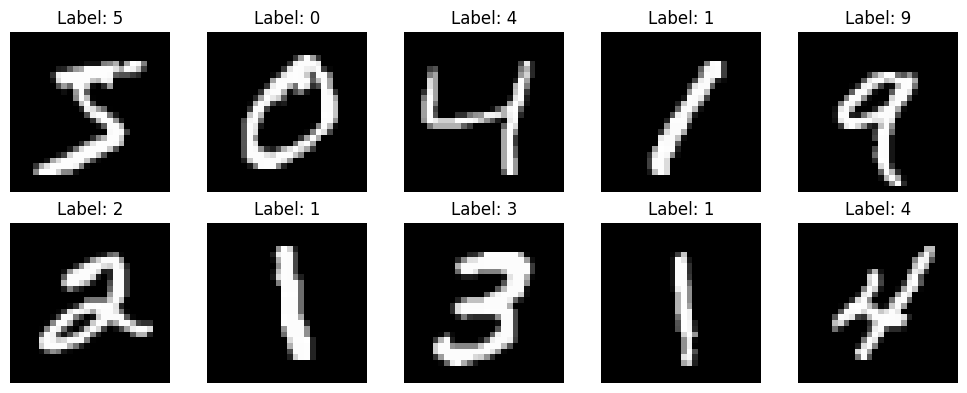

Normalized Shape: (60000, 28, 28, 1)
Normalized Pixel Range: -1.0 - 1.0
Dataset prepared successfully!
Batch Size: 128


In [2]:
# GANIKA R - 24BAD025
# TASK A: DATASET PREPARATION

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow Version:", tf.__version__)

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)
print("Pixel Value Range:", x_train.min(), "-", x_train.max())

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Normalize images between -1 and 1
x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape images
x_train = np.expand_dims(x_train, axis=-1)

print("Normalized Shape:", x_train.shape)
print("Normalized Pixel Range:", x_train.min(), "-", x_train.max())

# Prepare batches
BUFFER_SIZE = 60000
BATCH_SIZE = 128
noise_dim = 100

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE, drop_remainder=True)

print("Dataset prepared successfully!")
print("Batch Size:", BATCH_SIZE)

In [3]:
# TASK B: GENERATOR AND DISCRIMINATOR

# Generator Model
generator = keras.Sequential([
    layers.Input(shape=(noise_dim,)),
    layers.Dense(7 * 7 * 256, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Reshape((7, 7, 256)),

    layers.Conv2DTranspose(128, 5, strides=1,
                           padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(64, 5, strides=2,
                           padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(1, 5, strides=2,
                           padding='same', activation='tanh')
])

print("GENERATOR MODEL")
generator.summary()


# Discriminator Model
discriminator = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(64, 5, strides=2, padding='same'),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(128, 5, strides=2, padding='same'),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
])

print("DISCRIMINATOR MODEL")
discriminator.summary()


# Loss Functions
cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss


# Optimizers
generator_optimizer = keras.optimizers.Adam(1e-4)
discriminator_optimizer = keras.optimizers.Adam(1e-4)

print("Generator and Discriminator created successfully!")

GENERATOR MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

... (3 outputs left out)

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Generator and Discriminator created successfully!


Epoch 1/30 - Generator Loss: 0.9350 - Discriminator Loss: 0.9909
Epoch 2/30 - Generator Loss: 1.0957 - Discriminator Loss: 1.0948
Epoch 3/30 - Generator Loss: 0.9037 - Discriminator Loss: 1.2644
Epoch 4/30 - Generator Loss: 0.8406 - Discriminator Loss: 1.3040
Epoch 5/30 - Generator Loss: 0.8772 - Discriminator Loss: 1.2741
Epoch 6/30 - Generator Loss: 0.9192 - Discriminator Loss: 1.2252
Epoch 7/30 - Generator Loss: 1.0393 - Discriminator Loss: 1.1185
Epoch 8/30 - Generator Loss: 1.0553 - Discriminator Loss: 1.1307
Epoch 9/30 - Generator Loss: 1.0937 - Discriminator Loss: 1.1184
Epoch 10/30 - Generator Loss: 1.1117 - Discriminator Loss: 1.0816
Epoch 11/30 - Generator Loss: 1.1570 - Discriminator Loss: 1.0851
Epoch 12/30 - Generator Loss: 1.1837 - Discriminator Loss: 1.0760
Epoch 13/30 - Generator Loss: 1.2927 - Discriminator Loss: 1.0223
Epoch 14/30 - Generator Loss: 1.2355 - Discriminator Loss: 1.0484
Epoch 15/30 - Generator Loss: 1.1794 - Discriminator Loss: 1.0890
Epoch 16/30 - Gener

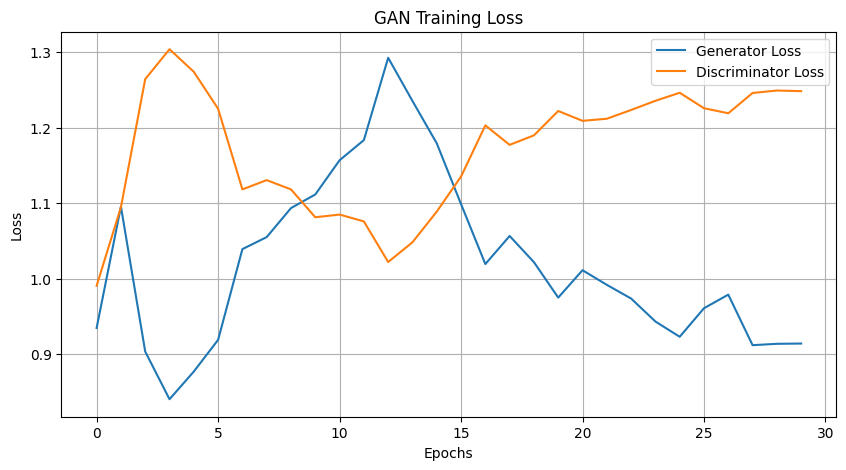

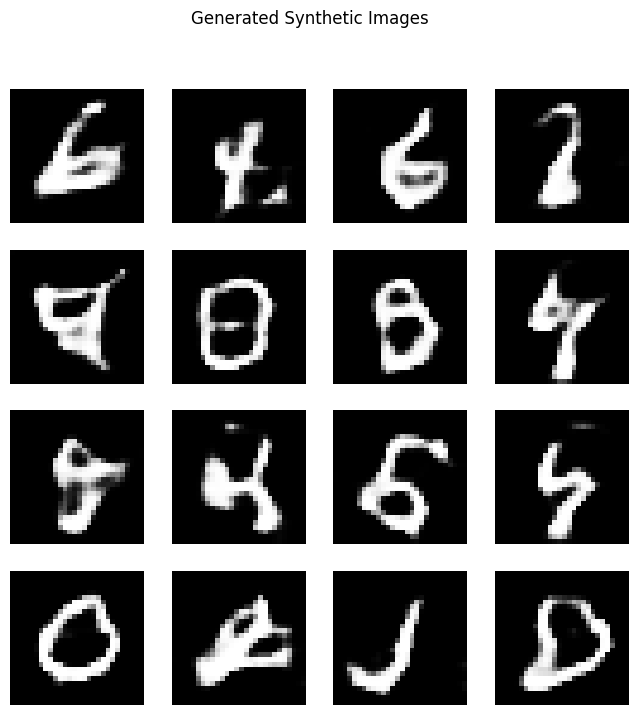

GAN Training Completed Successfully!


In [4]:
# TASK C: GAN TRAINING AND PERFORMANCE MONITORING

@tf.function
def train_step(images):

    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        (g, v) for g, v in zip(
            gen_gradients, generator.trainable_variables
        ) if g is not None
    )

    discriminator_optimizer.apply_gradients(
        (g, v) for g, v in zip(
            disc_gradients, discriminator.trainable_variables
        ) if g is not None
    )

    return gen_loss, disc_loss


# Train GAN
EPOCHS = 30

gen_losses = []
disc_losses = []

for epoch in range(EPOCHS):

    total_gen_loss = 0
    total_disc_loss = 0
    batches = 0

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        total_gen_loss += g_loss
        total_disc_loss += d_loss
        batches += 1

    avg_gen_loss = total_gen_loss / batches
    avg_disc_loss = total_disc_loss / batches

    gen_losses.append(float(avg_gen_loss))
    disc_losses.append(float(avg_disc_loss))

    print(f"Epoch {epoch+1}/{EPOCHS} - "
          f"Generator Loss: {avg_gen_loss:.4f} - "
          f"Discriminator Loss: {avg_disc_loss:.4f}")


# Plot losses
plt.figure(figsize=(10, 5))
plt.plot(gen_losses, label='Generator Loss')
plt.plot(disc_losses, label='Discriminator Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('GAN Training Loss')
plt.legend()
plt.grid()
plt.show()


# Generate sample images
noise = tf.random.normal([16, noise_dim])
generated_images = generator(noise, training=False)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(generated_images[i, :, :, 0] * 0.5 + 0.5,
               cmap='gray')
    plt.axis('off')

plt.suptitle("Generated Synthetic Images")
plt.show()

print("GAN Training Completed Successfully!")

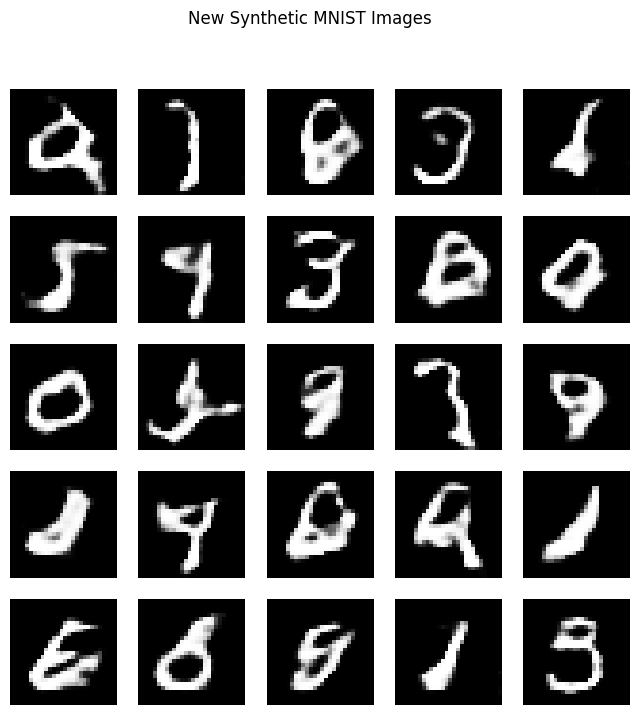

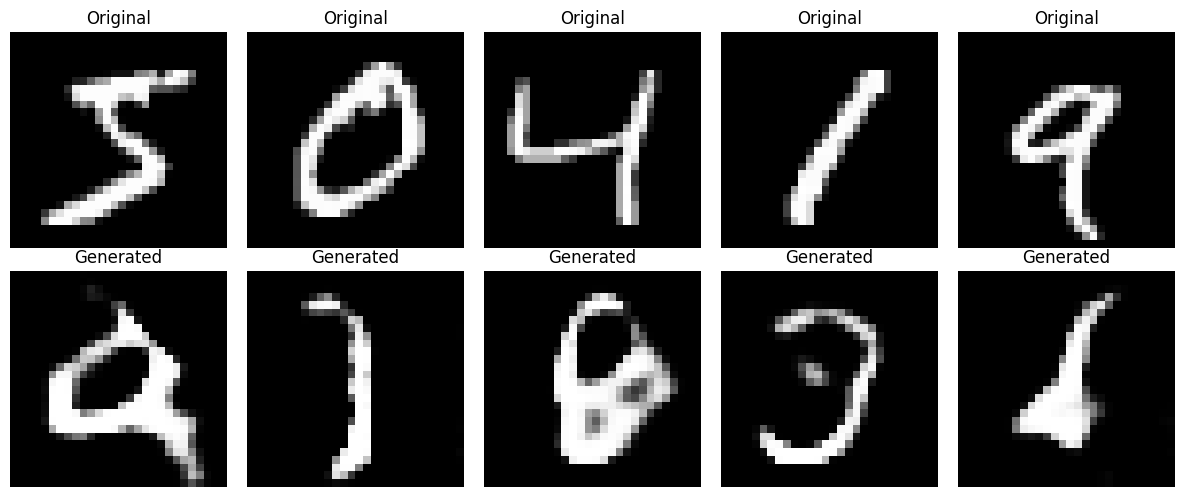

Generator model saved successfully!
Generated images saved successfully!

EXPERIMENT COMPLETED SUCCESSFULLY
Dataset: MNIST
Generator: Trained
Discriminator: Trained
Synthetic Images: Generated
Model: Saved


In [5]:
# TASK D: FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT

# Generate new synthetic images
new_noise = tf.random.normal([25, noise_dim])
synthetic_images = generator(new_noise, training=False)

# Display generated images
plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.imshow(synthetic_images[i, :, :, 0] * 0.5 + 0.5,
               cmap='gray')
    plt.axis('off')

plt.suptitle("New Synthetic MNIST Images")
plt.show()


# Compare original and generated images
plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i, :, :, 0] * 0.5 + 0.5,
               cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i+6)
    plt.imshow(synthetic_images[i, :, :, 0] * 0.5 + 0.5,
               cmap='gray')
    plt.title("Generated")
    plt.axis('off')

plt.tight_layout()
plt.show()


# Save Generator model
generator.save("GAN_Generator.keras")

print("Generator model saved successfully!")


# Save generated images
os.makedirs("generated_images", exist_ok=True)

for i in range(25):

    image = synthetic_images[i, :, :, 0].numpy()
    image = ((image + 1) * 127.5).clip(0, 255).astype(np.uint8)

    plt.imsave(
        f"generated_images/image_{i+1}.png",
        image,
        cmap='gray'
    )

print("Generated images saved successfully!")


# Final output
print("\nEXPERIMENT COMPLETED SUCCESSFULLY")
print("Dataset: MNIST")
print("Generator: Trained")
print("Discriminator: Trained")
print("Synthetic Images: Generated")
print("Model: Saved")